In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

In [3]:
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

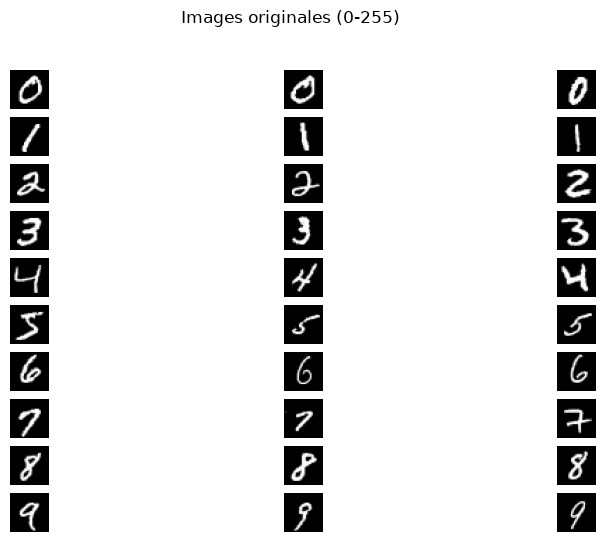

In [4]:
plt.figure(figsize=(10,6))
for digit in range(10):
    idx = np.where(y_train == digit)[0][:3]
    for i, j in enumerate(idx):
        plt.subplot(10,3, digit*3 + i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        plt.axis('off')
plt.suptitle("Images originales (0-255)")
plt.show()

In [6]:
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

In [7]:
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales :", X_train.shape, X_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


### 1. Prétraitement des données

Le jeu de données MNIST contient 70 000 images de chiffres manuscrits, réparties entre 60 000 images d'entraînement et 10 000 images de test. Chaque image mesure 28 × 28 pixels et est représentée en niveaux de gris.

La première étape consiste à normaliser les images en divisant les valeurs des pixels par 255. Cela permet de passer de valeurs comprises entre 0 et 255 à des valeurs comprises entre 0 et 1, ce qui facilite l'apprentissage du réseau.

Ensuite, np.expand_dims() ajoute une dimension correspondant au canal de couleur. Les images passent ainsi du format (28, 28) au format (28, 28, 1), nécessaire pour les couches Conv2D.

In [8]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)), 
    layers.Conv2D(64, (3, 3), activation='relu'),

    layers.Flatten(), 
    layers.Dense(128, activation='relu'), 
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [9]:
model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

### 2. Architecture du CNN

Le modèle est construit avec models.Sequential(), qui permet d'enchaîner plusieurs couches de neurones.

Input(28, 28, 1) : définit le format des images en entrée.  
Conv2D : applique des filtres pour détecter les caractéristiques des images, comme les contours et les formes. Le réseau utilise successivement 32, 64 et 64 filtres.  
MaxPooling2D : réduit les dimensions des cartes de caractéristiques afin de diminuer le nombre de calculs.   
Flatten : transforme les données multidimensionnelles en un vecteur.    
Dense(128) : combine les caractéristiques extraites pour reconnaître les chiffres.    
Dropout(0.5) : désactive aléatoirement des neurones pendant l'entraînement pour limiter le surapprentissage.    
Dense(10, softmax) : fournit les probabilités associées aux dix chiffres possibles, de 0 à 9.    

Le modèle est ensuite compilé avec l'optimiseur Adam, la fonction de perte sparse_categorical_crossentropy et la métrique accuracy. Ces paramètres définissent comment le réseau apprend et comment ses performances sont mesurées.

Enfin, model.summary() affiche la structure du réseau et le nombre de paramètres de chaque couche.

In [11]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, 
                    validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9172 - loss: 0.2677 - val_accuracy: 0.9853 - val_loss: 0.0477
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9769 - loss: 0.0783 - val_accuracy: 0.9898 - val_loss: 0.0348
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9831 - loss: 0.0578 - val_accuracy: 0.9880 - val_loss: 0.0375
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9869 - loss: 0.0449 - val_accuracy: 0.9910 - val_loss: 0.0321
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9885 - loss: 0.0387 - val_accuracy: 0.9907 - val_loss: 0.0320


### 3. Entraînement du modèle

L'entraînement est réalisé avec la méthode model.fit(), qui permet au CNN d'apprendre à reconnaître les chiffres à partir des images.

Plusieurs paramètres sont utilisés :

X_train et y_train : les images d'entraînement et leurs étiquettes.   
epochs=5 : le modèle effectue cinq passages sur les données d'apprentissage.    
batch_size=64 : les images sont traitées par lots de 64.    
validation_split=0.1 : 10 % des données d'entraînement sont utilisées pour vérifier les performances du modèle pendant l'apprentissage.  

À chaque étape, le réseau compare ses prédictions aux bonnes réponses et ajuste ses poids pour réduire les erreurs.

L'objectif est d'améliorer progressivement la précision du modèle tout en vérifiant sa capacité à reconnaître des images qui ne servent pas directement à l'apprentissage.

In [12]:
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.9933 - loss: 0.0233

Précision sur le test: 99.33%


In [13]:
y_pred =  np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


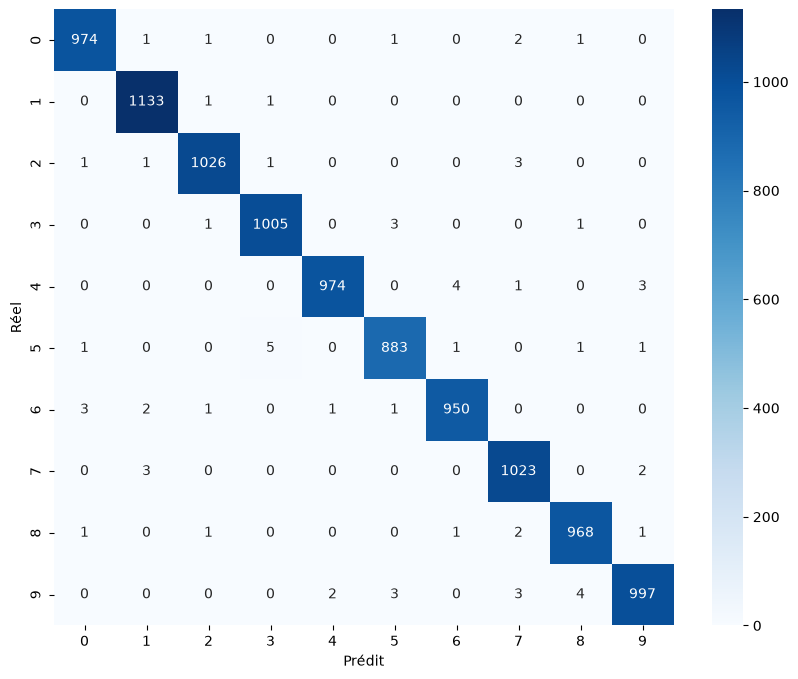

In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot = True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       1.00      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      1.00      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



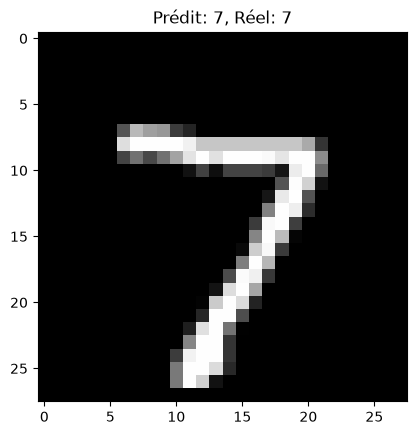

In [16]:
plt.imshow(X_test[0].reshape(28,28), cmap="gray")
plt.title(f"Prédit: {y_pred[0]}, Réel: {y_test[0]}")
plt.show()

### 4. Évaluation du modèle

Une fois l'entraînement terminé, le CNN est évalué sur les 10 000 images du jeu de test.

La méthode model.evaluate() permet de mesurer la perte et la précision du modèle sur des images qui n'ont pas été utilisées pour ajuster ses poids.

Ensuite, model.predict() génère les prédictions du réseau. La fonction np.argmax() sélectionne la classe ayant la probabilité la plus élevée.

La matrice de confusion permet de visualiser les bonnes prédictions et les erreurs. Les valeurs situées sur la diagonale correspondent aux chiffres correctement reconnus.

Le rapport de classification fournit des indicateurs complémentaires, comme la précision, le rappel et le F1-score (indicateur qui permet de mesurer la qualité des prédictions d'un modèle d'intelligence artificielle), pour chaque chiffre.

Enfin, une image du jeu de test est affichée avec le chiffre prédit et le chiffre réel afin de comparer visuellement le résultat.

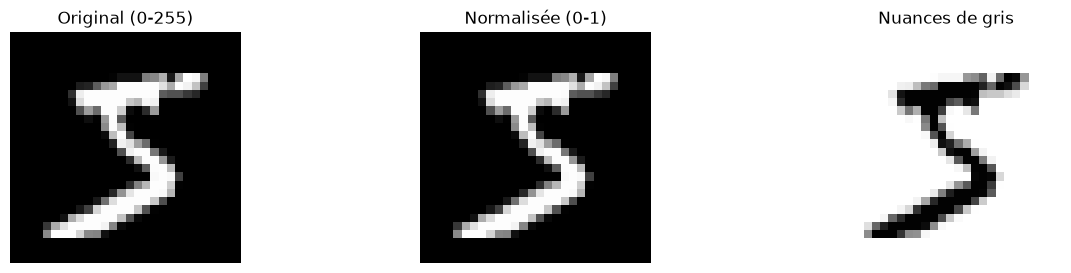

In [17]:
img = X_train_raw[y_train ==5][0]

plt.figure(figsize=(15,3))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original (0-255)")
plt.axis('off')

img_norm = img.astype("float32") / 2550
plt.subplot(1,3,2)
plt.imshow(img_norm, cmap='gray')
plt.title("Normalisée (0-1)")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_norm, cmap='Greys')
plt.title("Nuances de gris")
plt.axis('off')

plt.show()